In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import math

In [2]:
clinical_data = pd.read_csv("datasets/clinical_data.csv")
lab_data1 = pd.read_csv("datasets/lab_data.csv")

Filtering data for 30 days

In [3]:
preop = lab_data1[(lab_data1['dt'] < 0) & (lab_data1['dt'] >= -2592000)] #30 days

preop_last = (preop.sort_values('dt').groupby(['caseid', 'name']).last()   
              .reset_index()[['caseid','dt', 'name', 'result']])

preop_last.head(10)
print("pre-op rows:", len(preop))

pre-op rows: 196862


In [4]:
preop.groupby("name")["dt"].describe()
print("median hours before surgery:", (preop_last["dt"].abs()/3600).median())

median hours before surgery: 29.634444444444444


In [5]:
lab_data = (preop_last
            .pivot(index="caseid", columns="name", values="result")
            .reset_index())
lab_data.columns.name = None

lab_cols = [c for c in lab_data.columns if c != "caseid"]
lab_data[lab_cols] = lab_data[lab_cols].apply(pd.to_numeric, errors="coerce")

lab_data.head(10)
print(lab_data.shape)
print(clinical_data.shape)

(5388, 35)
(6388, 74)


filtering columns that have more than 75 missing data

In [6]:
missing_rate = lab_data.isna().mean()
lab_data = lab_data.loc[:, missing_rate < 0.75]
print("after 75% filter:", lab_data.shape)
lab_data


after 75% filter: (5388, 24)


,caseid,alb,alt,aptt,ast,bun,cl,cr,crp,fib,...,k,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc
0,1,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,...,3.5,141.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,NaN,NaN,NaN,NaN,NaN,115.0,NaN,NaN,NaN,...,4.7,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36
2,4,NaN,NaN,NaN,NaN,NaN,108.0,NaN,NaN,NaN,...,4.3,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5,4.6,30.0,36.5,64.0,27.0,108.0,1.83,NaN,178.0,...,4.9,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64
4,6,3.9,17.0,29.1,19.0,14.0,104.0,1.07,0.01,183.0,...,3.4,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5383,6384,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.2,143.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5384,6385,3.7,28.0,NaN,18.0,19.0,109.0,0.84,NaN,NaN,...,4.0,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45
5385,6386,NaN,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,...,4.5,142.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5386,6387,4.4,10.0,32.2,16.0,7.0,103.0,0.65,0.03,239.0,...,3.6,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70


Remove physiologically impossible values only

In [7]:
lab_data = lab_data[lab_data["hct"].between(10, 65) | lab_data["hct"].isna()]
for c in ["height", "weight", "bmi"]:
    clinical_data.loc[clinical_data[c] <= 0, c] = np.nan
print("lab_data after plausibility filter:", lab_data.shape)
print("clinical_data after plausibility filter:", clinical_data.shape)

lab_data after plausibility filter: (5388, 24)
clinical_data after plausibility filter: (6388, 74)


Fix the syntax error in error

In [8]:
clinical_data["age"] = clinical_data["age"].replace(">89", 90)
clinical_data["age"] = pd.to_numeric(clinical_data["age"], errors="coerce")

Merge 2 dataframes with common IDs

In [9]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")

start building the decision tree

In [10]:
import pandas as pd
from scipy.stats import pearsonr

merged_data = clinical_data.merge(lab_data, on="caseid", how="inner")
merged_data["sex_bin"] = (merged_data["sex"] == "M").astype(int)

predictors = ["sex_bin", "age", "height", "weight", "bmi"]

results = []
for col in predictors:
    sub = merged_data[[col, "hct"]].dropna()   # pairwise deletion, like .corr()
    r, p = pearsonr(sub[col], sub["hct"])
    results.append({"variable": col, "pearson_r": r, "p_value": p, "n": len(sub)})

corr_df = pd.DataFrame(results)
print(corr_df)

  variable  pearson_r        p_value     n
0  sex_bin   0.241466   5.681913e-56  4138
1      age  -0.061301   7.950962e-05  4138
2   height   0.257384   1.323553e-63  4138
3   weight   0.365879  2.846304e-131  4138
4      bmi   0.265882   6.616834e-68  4138


In [11]:
merged_data

,caseid,subjectid,casestart,caseend,anestart,aneend,opstart,opend,adm,dis,...,na,p,plt,pt%,ptinr,ptsec,tbil,tprot,wbc,sex_bin
0,1,5955,0,11542,-552,10848.0,1668,10368,-236220,627780,...,141.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,2,2487,0,15741,-1039,14921.0,1721,14621,-221160,1506840,...,143.0,NaN,251.0,NaN,NaN,NaN,NaN,NaN,4.36,1
2,4,1903,0,20990,-778,20222.0,2522,17822,-201120,576480,...,144.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,5,4416,0,21531,-1009,22391.0,2591,20291,-67560,3734040,...,139.0,5.4,158.0,81.0,1.14,13.0,0.9,8.2,14.64,1
4,6,5586,0,5145,-51,4749.0,2649,4449,-300600,131400,...,141.0,2.8,145.0,104.0,0.97,11.1,1.0,6.7,3.20,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5383,6384,5583,0,15248,-260,15640.0,2140,14140,-215340,648660,...,143.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
5384,6385,2278,0,20643,-544,20996.0,2396,19496,-225600,1675200,...,144.0,NaN,239.0,NaN,NaN,NaN,0.6,5.9,5.45,1
5385,6386,4045,0,19451,-667,19133.0,3533,18233,-200460,836340,...,142.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
5386,6387,5230,0,12025,-550,12830.0,1730,11030,-227760,377040,...,142.0,3.0,214.0,90.0,1.07,12.2,0.3,6.9,7.70,0


Drop the rows where "hct" does not exist

In [27]:
merged_data = merged_data.dropna(subset=['hct','sex_bin','height','weight','bmi'])
merged_data['hct'].mean()

np.float64(38.05896568390527)

In [30]:
print(merged_data['hct'].max())
print(merged_data['hct'].min())

61.2
13.4


Using sklearn

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier 

Implementation

set up the data

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


merged_data.shape
merged_data.head()
X = merged_data[['sex_bin','height','weight','bmi']]
y = merged_data['hct']

RANDOM_STATE = 42  
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)


serching for the max_depth fro 1 up to 15

In [47]:
param_grid = {'max_depth': list(range(1,16))}
print(param_grid)

{'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]}


Running Cross_Validation

In [52]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# base model
dt = DecisionTreeRegressor(random_state=42)

#set up the 5 fold cross validation grid search
grid_search = GridSearchCV(estimator = dt, param_grid = param_grid, cv = 5, scoring = 'neg_mean_squared_error')

grid_search.fit(X_train, y_train)

,estimator,DecisionTreeR...ndom_state=42)
,param_grid,"{'max_depth': [1, 2, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


Extract optimal max_depth

In [53]:
best_depth = grid_search.best_params_['max_depth']
best_model = grid_search.best_estimator_

print(f"optimal best max_depth found: {best_depth}")
print(f"Best Validation Accuracy: {grid_search.best_score_:.4f}")

optimal best max_depth found: 3
Best Validation Accuracy: -25.3334


Eval the final prediction

In [56]:
y_pred = best_model.predict(X_test)

test_acc = r2_score(y_test, y_pred)
print(test_acc)

0.14817252216349674


trtjrtjktk

In [58]:
from sklearn.tree import DecisionTreeRegressor

classifier = DecisionTreeRegressor(criterion = 'absolute_error', max_depth=3)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

# Evaluate the regression predictions
print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error (MAE): 3.8182367149758454
Mean Squared Error (MSE): 25.14535024154589
R2 Score: 0.11355331857491358


In [60]:
from sklearn import tree
text_representation = tree.export_text(classifier)
print(text_representation)

|--- feature_2 <= 59.25
|   |--- feature_2 <= 48.65
|   |   |--- feature_2 <= 23.82
|   |   |   |--- value: [28.10]
|   |   |--- feature_2 >  23.82
|   |   |   |--- value: [35.00]
|   |--- feature_2 >  48.65
|   |   |--- feature_3 <= 17.95
|   |   |   |--- value: [35.00]
|   |   |--- feature_3 >  17.95
|   |   |   |--- value: [37.40]
|--- feature_2 >  59.25
|   |--- feature_0 <= 0.50
|   |   |--- feature_1 <= 161.45
|   |   |   |--- value: [37.90]
|   |   |--- feature_1 >  161.45
|   |   |   |--- value: [36.60]
|   |--- feature_0 >  0.50
|   |   |--- feature_2 <= 71.88
|   |   |   |--- value: [40.50]
|   |   |--- feature_2 >  71.88
|   |   |   |--- value: [42.40]



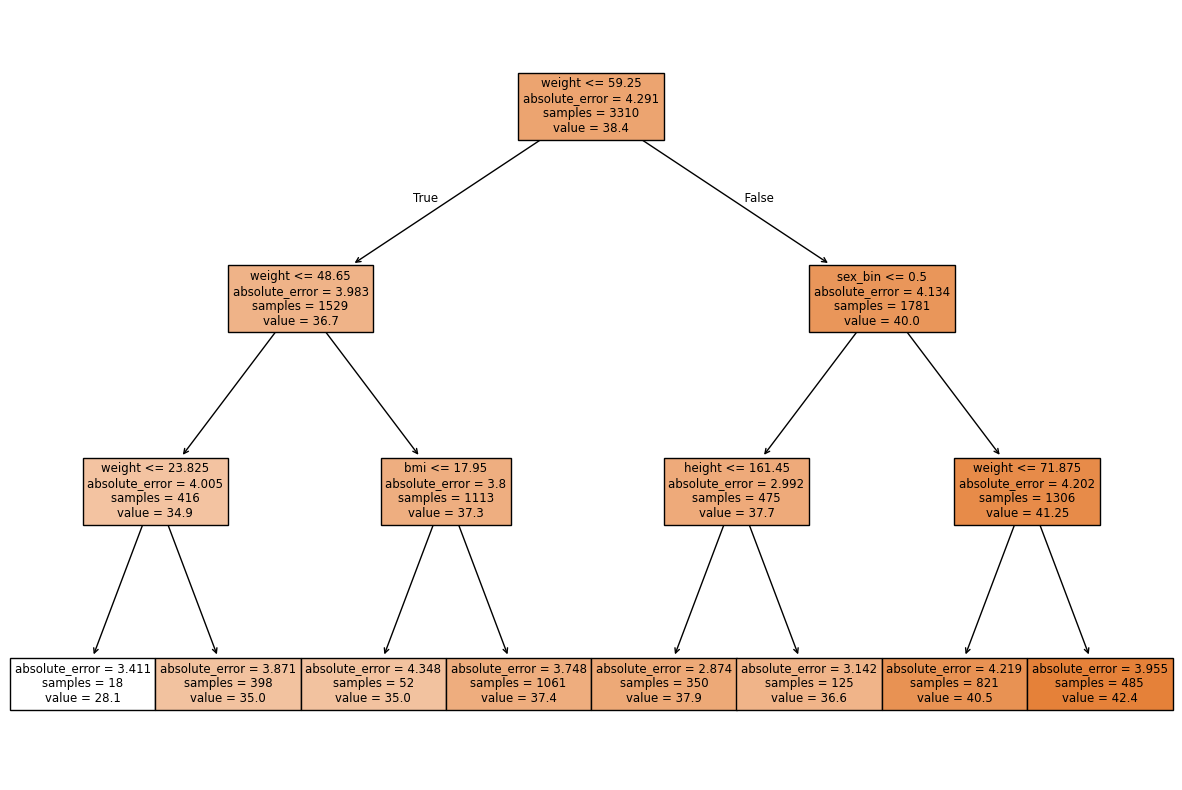

In [61]:
from sklearn.tree import plot_tree

plt.figure(figsize=(15,10))
plot_tree(classifier, feature_names = X.columns, filled = True)
plt.show()